# code_165 · Learning across structural tasks and conditioning on support

**Book:** section 31.5. A self-contained limited-label learning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_31_GUIDE.md), [run evidence](../CHAPTER_31_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_165).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json,copy,hashlib
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=4265;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 4265


<a id="task-episodes-and-meta-objective"></a>
 ## New tasks require new mechanisms, not only new rows
 Each generated structural family has response y=a*x+b*x^3 plus measurement noise, with its own coefficients. Seventy source tasks each supply 64 cases;20 separate development tasks supply support/query evidence. Final assessment uses 40 new familiar-prior tasks and 40 changed-prior tasks with larger nonlinear coefficients. Compare actual second-order MAML-style training of a two-parameter initialization, pooled source least squares, zero initialization and a frozen context network. The context network takes seven support sufficient-statistic inputs and emits two per-request coefficients; global weights never change at final inference. Support-only least squares is an independent reference. Across 800 source updates, MAML and the context network share recorded source episodes with disjoint support/query indices. No final task or label enters source learning. Development selects adaptation steps 1/5/20 for each gradient method at each support budget 2/4/8.


,domain,method,support_labels_per_task,query_cases_per_task,final_tasks,mean_task_MAE,SD_task_MAE,inner_gradient_steps
0,New familiar-prior tasks,Meta initialization,2,32,40,0.069464,0.052942,20
1,New familiar-prior tasks,Pooled initialization,2,32,40,0.067060,0.052855,20
2,New familiar-prior tasks,Zero initialization,2,32,40,0.190439,0.172225,20
3,New familiar-prior tasks,Frozen context network,2,32,40,0.073446,0.066102,0
4,New familiar-prior tasks,Support least squares,2,32,40,2.430940,13.979432,0
5,New familiar-prior tasks,Meta initialization,4,32,40,0.058929,0.040807,20
6,New familiar-prior tasks,Pooled initialization,4,32,40,0.056907,0.039371,20
7,New familiar-prior tasks,Zero initialization,4,32,40,0.166430,0.156073,20
8,New familiar-prior tasks,Frozen context network,4,32,40,0.061271,0.058183,0
9,New familiar-prior tasks,Support least squares,4,32,40,0.063721,0.128873,0


Selected source updates: 800 800


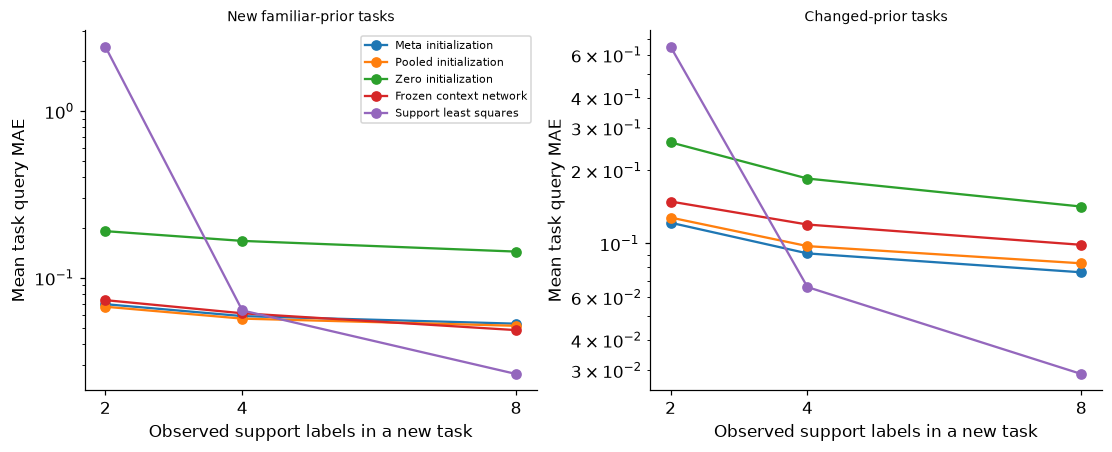

In [2]:
def tasks(n,offset,changed=False):
    a=rng.uniform(.5,2.,n);b=rng.uniform(.4,.8,n) if changed else rng.uniform(-.15,.15,n);x=rng.uniform(-1,1,(n,64));phi=np.stack([x,x**3],-1);y=a[:,None]*x+b[:,None]*x**3+rng.normal(0,.03,(n,64));return torch.tensor(phi),torch.tensor(y),np.arange(offset,offset+n)
SP,SY,source_ids=tasks(70,0);DP,DY,dev_ids=tasks(20,1000);FP,FY,final_ids=tasks(40,2000);NP,NY,new_ids=tasks(40,3000,True);assert len(set(np.r_[source_ids,dev_ids,final_ids,new_ids]))==170
generator=np.random.default_rng(SEED+9);plans=[];admitted=np.zeros((70,64),bool)
for step in range(800):
    episode=[]
    for task in generator.choice(70,8,replace=False):
        ids=generator.choice(64,24,replace=False);k=4 if step%2==0 else 8;support=ids[:k];query=ids[k:];assert not set(support)&set(query);episode.append((int(task),support,query));admitted[task,ids]=True
    plans.append(episode)
def adapt(theta,p,y,steps,create_graph=False):
    fast=theta
    for _ in range(steps):
        loss=((p@fast-y)**2).mean();gradient=torch.autograd.grad(loss,fast,create_graph=create_graph)[0];fast=fast-.1*gradient
    return fast
def stats(p,y):return torch.cat([(p*y[:,None]).mean(0),(p.T@p/len(p)).flatten(),torch.tensor([len(p)/8.])])
class ContextNetwork(nn.Module):
    def __init__(self):super().__init__();self.net=nn.Sequential(nn.Linear(7,32),nn.Tanh(),nn.Linear(32,32),nn.Tanh(),nn.Linear(32,2))
    def forward(self,p,y,q):return q@self.net(stats(p,y))
torch.manual_seed(SEED);theta=nn.Parameter(torch.zeros(2));context=ContextNetwork();meta_opt=torch.optim.Adam([theta],lr=.01);context_opt=torch.optim.Adam(context.parameters(),lr=.003);best_meta=np.inf;best_context=np.inf;trace=[]
def dev_score(initial,steps=2,k=4):
    values=[]
    for p,y in zip(DP,DY):
        fast=adapt(initial.detach().clone().requires_grad_(True),p[:k],y[:k],steps);values.append(float(((p[8:40]@fast-y[8:40])**2).mean().detach()))
    return float(np.mean(values))
for step,episode in enumerate(plans):
    meta_losses=[];context_losses=[]
    for task,support,query in episode:
        p,y=SP[task],SY[task];fast=adapt(theta,p[support],y[support],2,True);meta_losses.append(((p[query]@fast-y[query])**2).mean());context_losses.append(((context(p[support],y[support],p[query])-y[query])**2).mean())
    meta_loss=torch.stack(meta_losses).mean();context_loss=torch.stack(context_losses).mean();meta_opt.zero_grad();meta_loss.backward();meta_opt.step();context_opt.zero_grad();context_loss.backward();context_opt.step()
    if (step+1)%100==0:
        mdv=dev_score(theta)
        with torch.no_grad():cdv=float(np.mean([float(((context(p[:4],y[:4],p[8:40])-y[8:40])**2).mean()) for p,y in zip(DP,DY)]))
        trace.append((step+1,mdv,cdv))
        if mdv<best_meta:best_meta=mdv;meta_state=theta.detach().clone();selected_meta=step+1
        if cdv<best_context:best_context=cdv;context_state=copy.deepcopy(context.state_dict());selected_context=step+1
context.load_state_dict(context_state);context.eval();pooled=torch.linalg.lstsq(SP.reshape(-1,2),SY.flatten()).solution.detach();initials={'Meta initialization':meta_state,'Pooled initialization':pooled,'Zero initialization':torch.zeros(2)};selected_steps={};rows=[]
for name,initial in initials.items():
    for k in [2,4,8]:selected_steps[(name,k)]=min([1,5,20],key=lambda steps:dev_score(initial,steps,k))
digest=lambda model:hashlib.sha256(b''.join(p.detach().numpy().tobytes() for p in model.parameters())).hexdigest();before=digest(context)
for domain,phi,y in [('New familiar-prior tasks',FP,FY),('Changed-prior tasks',NP,NY)]:
    for k in [2,4,8]:
        methods=list(initials)+['Frozen context network','Support least squares'];per_task={name:[] for name in methods}
        for p,target in zip(phi,y):
            support,query=p[:k],p[8:40];sy=target[:k];qy=target[8:40]
            for name,initial in initials.items():
                fast=adapt(initial.clone().requires_grad_(True),support,sy,selected_steps[(name,k)]);per_task[name].append(float(torch.abs(query@fast-qy).mean().detach()))
            with torch.no_grad():prediction=context(support,sy,query);coeff=torch.linalg.lstsq(support,sy).solution;per_task['Frozen context network'].append(float(torch.abs(prediction-qy).mean()));per_task['Support least squares'].append(float(torch.abs(query@coeff-qy).mean()))
        for name,values in per_task.items():rows.append({'domain':domain,'method':name,'support_labels_per_task':k,'query_cases_per_task':32,'final_tasks':40,'mean_task_MAE':float(np.mean(values)),'SD_task_MAE':float(np.std(values,ddof=1)),'inner_gradient_steps':selected_steps.get((name,k),0)})
assert before==digest(context) and admitted.all();RESULTS.update(source_tasks=70,source_unique_labels=int(admitted.sum()),source_labels_per_task=64,development_tasks=20,development_support_labels_max=160,development_query_labels=640,final_familiar_tasks=40,final_changed_tasks=40,source_optimizer_updates=800,source_tasks_per_episode_batch=8,meta_inner_steps=2,meta_inner_learning_rate=.1,second_order_meta_gradients=True,selected_meta_update=selected_meta,selected_context_update=selected_context,context_global_parameters=sum(p.numel() for p in context.parameters()),selected_inner_steps=[{'method':name,'support_labels':k,'steps':steps} for (name,k),steps in selected_steps.items()],metrics=rows,context_weights_unchanged=True,final_support_query_overlap=0,final_task_overlap_with_source=0);display(pd.DataFrame(rows));print('Selected source updates:',selected_meta,selected_context)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,domain in zip(axes,['New familiar-prior tasks','Changed-prior tasks']):
    for name in list(initials)+['Frozen context network','Support least squares']:
        rr=[r for r in rows if r['domain']==domain and r['method']==name];ax.plot([r['support_labels_per_task'] for r in rr],[r['mean_task_MAE'] for r in rr],marker='o',label=name)
    ax.set(xticks=[2,4,8],xlabel='Observed support labels in a new task',ylabel='Mean task query MAE',title=domain)
for ax in axes:ax.set_yscale('log')
axes[0].legend(fontsize=7);plt.show()


<a id="global-weights-and-request-conditioning"></a>
 ## An episode has an information boundary of its own
 Meta-training differentiates the query loss through two support-gradient steps; create_graph=True retains the second-order dependency on the shared initialization. This is an actual meta-objective, unlike ordinary pooled fitting followed by fine-tuning. The frozen context network instead consumes support statistics as inputs and predicts request-specific coefficients with unchanged global weights. This small conditional hypernetwork illustrates fixed-weight conditioning, not a claim to reproduce language-model in-context learning. All source labels are reused across episodes and counted once as unique outcomes;800 updates are not 800 independent tasks. Every final query starts after the first eight reserved support positions, even at the two-label budget, so unused support cases never become query outcomes. Changed coefficient ranges test an altered task prior, not merely a new row split.


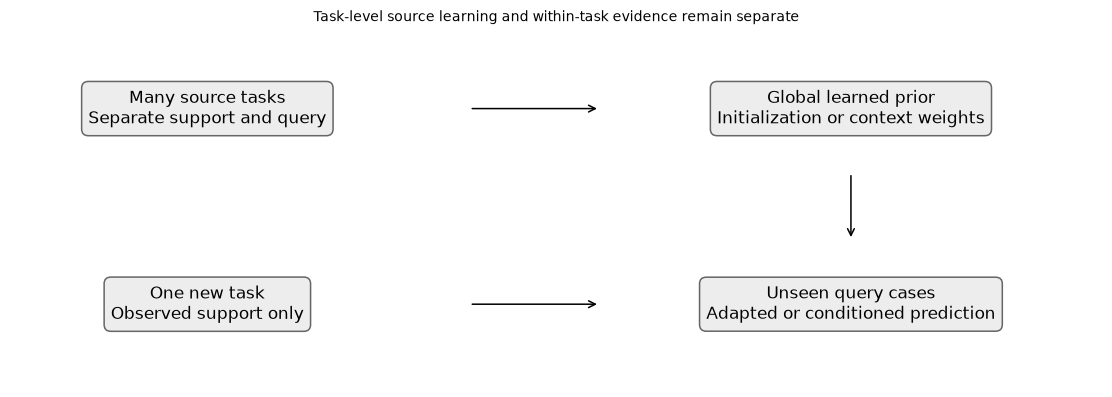

In [3]:
fig,ax=plt.subplots(figsize=(10,3.5));ax.axis('off');positions=[(.18,.78),(.77,.78),(.18,.23),(.77,.23)];labels=['Many source tasks\nSeparate support and query','Global learned prior\nInitialization or context weights','One new task\nObserved support only','Unseen query cases\nAdapted or conditioned prediction']
for pos,label in zip(positions,labels):ax.text(*pos,label,ha='center',va='center',transform=ax.transAxes,bbox={'boxstyle':'round,pad=.4','facecolor':'.93','edgecolor':'.4'})
for a,b in [((.42,.78),(.54,.78)),((.77,.60),(.77,.41)),((.42,.23),(.54,.23))]:ax.annotate('',xy=b,xytext=a,xycoords='axes fraction',arrowprops={'arrowstyle':'->'})
ax.set_title('Task-level source learning and within-task evidence remain separate');plt.show()
assert len(rows)==30 and len(selected_steps)==9 and all(np.isfinite(r['mean_task_MAE']) for r in rows)


In [4]:
summary={'example_id':'code_165','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual second-order gradient-based meta-training across task episodes', 'pooled source fitting scratch adaptation and support-only least-squares controls', 'actual frozen context network maps support statistics into task predictions', 'new task identities and changed task-parameter prior evaluated separately', 'development-only adaptation-step selection and audited source label access'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual second-order gradient-based meta-training across task episodes", "pooled source fitting scratch adaptation and support-only least-squares controls", "actual frozen context network maps support statistics into task predictions", "new task identities and changed task-parameter prior evaluated separately", "development-only adaptation-step selection and audited source label access"], "elapsed_seconds": 2.777, "example_id": "code_165", "hardware": "Darwin arm64 CPU", "results": {"context_global_parameters": 1378, "context_weights_unchanged": true, "development_query_labels": 640, "development_support_labels_max": 160, "development_tasks": 20, "final_changed_tasks": 40, "final_familiar_tasks": 40, "final_support_query_overlap": 0, "final_task_overlap_with_source": 0, "meta_inner_learning_rate": 0.1, "meta_inner_steps": 2, "metrics": [{"SD_task_MAE": 0.05294242071038682, "domain": "New familiar-prior tasks", "final_tasks": 40, "inner_